# TradeKriya: 5-Year Structural Personality & Safety Profiling Engine

### Quantitative Problem Statement
In real-world trading, different stocks exhibit drastically different behavioral regimes across Demand and Supply zones:
1. **Falling-Zone Risk (Cascade Breakdowns)**: Stocks in secular downtrends or capital-destructive phases that continuously shatter demand zones. Buying the dip on these stocks turns into a "falling knife" trap.
2. **Expansion Runners (Supply Breakers)**: High-momentum compounders that rarely respect overhead resistance and break out to new highs more often than mean-reverting.
3. **Mean-Reversion Oscillators**: Clean, cyclical range-bound stocks that reliably bounce off support and reject resistance.
4. **Safe D&S Anchors**: Institutional favorites with high support integrity, low tail drawdowns, and high bounce probability upon entering demand.

This notebook evaluates every stock over **5 years (~1,270 trading sessions)** across **6 quantitative parameters** to classify their behavioral DNA and label them with a **Safety Score (0 to 100)**.


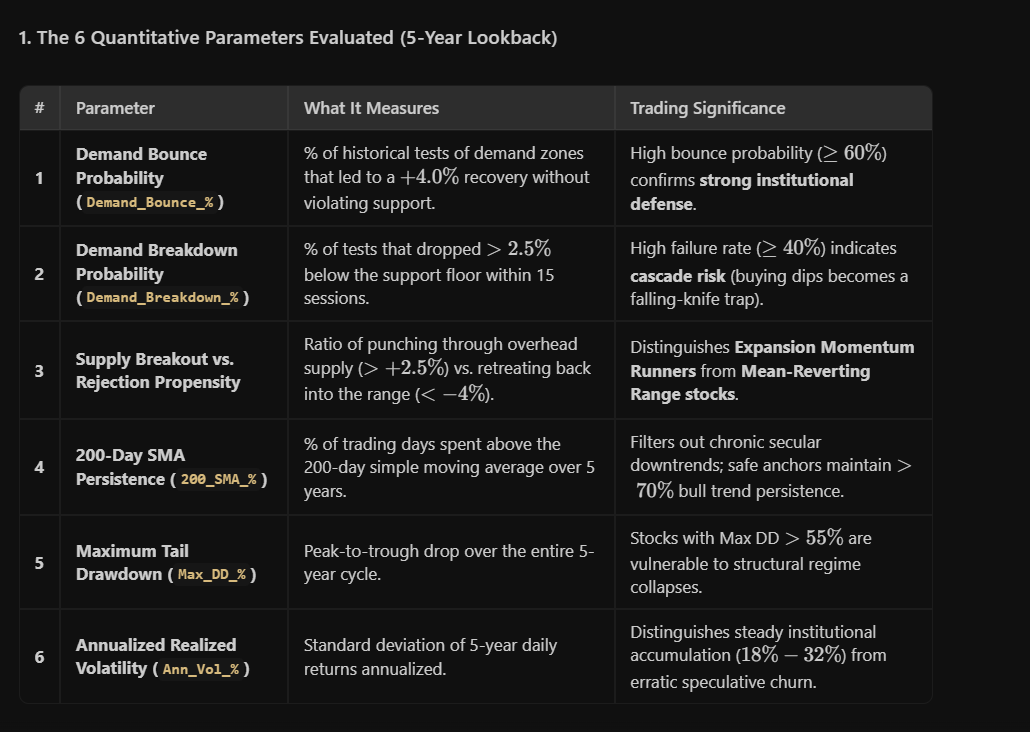

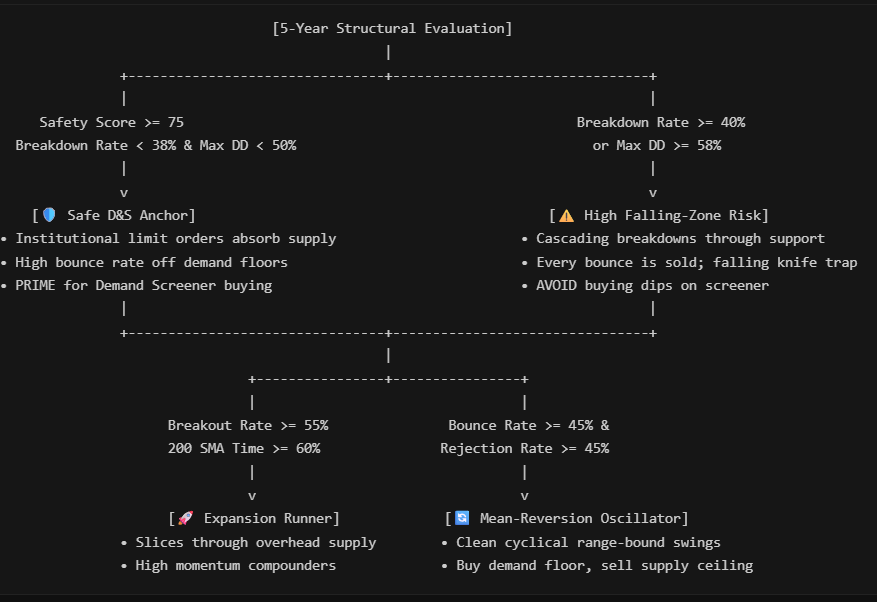

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from datetime import datetime

# Set institutional dark theme styling
plt.style.use('dark_background')
plt.rcParams['font.sans-serif'] = 'Segoe UI', 'DejaVu Sans', 'Helvetica'
plt.rcParams['axes.edgecolor'] = '#30363d'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#21262d'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.6

DATA_PATH = 'screener/data/fo_historical_dump.json'
with open(DATA_PATH, 'r') as f:
    raw_dump = json.load(f)

print(f"Loaded {len(raw_dump)} tickers from {DATA_PATH}")


Loaded 115 tickers from screener/data/fo_historical_dump.json


In [2]:
def parse_df(records):
    """Converts raw records to sorted DataFrame."""
    df = pd.DataFrame(records, columns=['date', 'open', 'high', 'low', 'close', 'volume'])
    df['date'] = pd.to_datetime(df['date'].astype(str).str.slice(0, 10))
    df = df.sort_values('date').reset_index(drop=True)
    for c in ['open', 'high', 'low', 'close', 'volume']:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    return df

universe_dfs = {}
for sym, records in raw_dump.items():
    if len(records) >= 300:
        universe_dfs[sym] = parse_df(records)

print(f"Ingested {len(universe_dfs)} stocks with long multi-year history.")
sample_sym = 'BHARTIARTL'
print(f"Sample Stock ({sample_sym}): {len(universe_dfs[sample_sym])} bars from {universe_dfs[sample_sym]['date'].iloc[0].strftime('%Y-%m-%d')} to {universe_dfs[sample_sym]['date'].iloc[-1].strftime('%Y-%m-%d')}")


Ingested 115 stocks with long multi-year history.
Sample Stock (BHARTIARTL): 1279 bars from 2021-08-23 to 2026-10-16


In [3]:
def compute_5y_structural_profile(symbol, df):
    """
    Evaluates 6 core quantitative dimensions over trailing 5 years:
    1. Demand Bounce Probability (Support Integrity)
    2. Demand Breakdown Probability (Falling Zone Cascade Risk)
    3. Supply Breakout vs Rejection Propensity
    4. 200-Day SMA Bullish Persistence (% of trading days above 200 SMA)
    5. Maximum Tail Drawdown (Max DD)
    6. Annualized Realized Volatility
    """
    df = df.copy()
    
    # ATR & Trend Indicators
    tr = pd.concat([
        df['high'] - df['low'],
        (df['high'] - df['close'].shift(1)).abs(),
        (df['low'] - df['close'].shift(1)).abs()
    ], axis=1).max(axis=1)
    df['atr'] = tr.ewm(alpha=1/14, min_periods=14, adjust=False).mean()
    df['sma_200'] = df['close'].rolling(200).mean()
    
    # 1. 200-Day SMA Bullish Persistence
    valid_sma = df.dropna(subset=['sma_200'])
    pct_above_200 = float((valid_sma['close'] > valid_sma['sma_200']).mean() * 100.0) if len(valid_sma) > 0 else 50.0
    
    # 2. Maximum Tail Drawdown
    peak = df['close'].cummax()
    dd = (df['close'] - peak) / peak
    max_dd = float(abs(dd.min() * 100.0))
    
    # 3. Realized Annualized Volatility
    pct_rets = df['close'].pct_change().dropna()
    ann_vol = float(pct_rets.std() * np.sqrt(252) * 100.0)
    
    # 4. Vectorized Local Pivot Detection (5-bar window)
    lows = df['low'].values
    highs = df['high'].values
    
    is_pivot_low = (lows[2:-2] < lows[1:-3]) & (lows[2:-2] < lows[:-4]) & (lows[2:-2] < lows[3:-1]) & (lows[2:-2] < lows[4:])
    pivot_low_indices = np.where(is_pivot_low)[0] + 2
    
    is_pivot_high = (highs[2:-2] > highs[1:-3]) & (highs[2:-2] > highs[:-4]) & (highs[2:-2] > highs[3:-1]) & (highs[2:-2] > highs[4:])
    pivot_high_indices = np.where(is_pivot_high)[0] + 2
    
    # Evaluate Historical Demand Tests (Forward 15-session outcomes)
    bounces = 0
    breakdowns = 0
    d_tests = 0
    for idx in pivot_low_indices[:-1]:
        p_low = lows[idx]
        fwd_low = lows[idx+1 : min(len(df), idx+15)]
        fwd_high = highs[idx+1 : min(len(df), idx+15)]
        if len(fwd_low) == 0: continue
        d_tests += 1
        # Breakdown: Slices more than 2.5% below pivot floor
        if np.min(fwd_low) < p_low * 0.975:
            breakdowns += 1
        # Bounce: Stages a +4.0% recovery off pivot floor
        elif np.max(fwd_high) > p_low * 1.04:
            bounces += 1
            
    demand_bounce_rate = (bounces / d_tests * 100.0) if d_tests > 0 else 50.0
    demand_breakdown_rate = (breakdowns / d_tests * 100.0) if d_tests > 0 else 50.0
    
    # Evaluate Historical Supply Tests
    breakouts = 0
    rejections = 0
    s_tests = 0
    for idx in pivot_high_indices[:-1]:
        p_high = highs[idx]
        fwd_high = highs[idx+1 : min(len(df), idx+15)]
        fwd_low = lows[idx+1 : min(len(df), idx+15)]
        if len(fwd_high) == 0: continue
        s_tests += 1
        # Breakout: Clears more than 2.5% above pivot ceiling
        if np.max(fwd_high) > p_high * 1.025:
            breakouts += 1
        # Rejection: Drops more than 4.0% off ceiling
        elif np.min(fwd_low) < p_high * 0.96:
            rejections += 1
            
    supply_breakout_rate = (breakouts / s_tests * 100.0) if s_tests > 0 else 50.0
    supply_rejection_rate = (rejections / s_tests * 100.0) if s_tests > 0 else 50.0

    # 5. Safety Score Calibration (0 to 100)
    score = 0
    score += min(30, (demand_bounce_rate / 60.0) * 30)                  # Support bounce ability (up to 30 pts)
    score += max(0, min(20, (1.0 - (demand_breakdown_rate - 20) / 40.0) * 20)) # Low breakdown risk (up to 20 pts)
    score += max(0, min(20, (1.0 - (max_dd - 20) / 40.0) * 20))        # Tail risk control (up to 20 pts)
    score += min(15, (pct_above_200 / 70.0) * 15)                       # Macro bull trend (up to 15 pts)
    score += 15 if (18 <= ann_vol <= 32) else (10 if ann_vol < 18 else max(0, 15 - (ann_vol - 32)*0.5)) # Volatility (up to 15 pts)
    
    safety_score = round(min(100.0, max(0.0, score)), 1)
    
    # 6. Structural Behavioral Classification
    if demand_breakdown_rate >= 42.0 or max_dd >= 58.0:
        label = "High Falling-Zone Risk"
        recommendation = "AVOID Buying Dips (Cascade traps; demand levels fail repeatedly)"
    elif supply_breakout_rate >= 45.0 and pct_above_200 >= 60.0:
        label = "Expansion Runner"
        recommendation = "Breakout Favored (Regularly punches through overhead supply)"
    elif safety_score >= 75.0 and demand_breakdown_rate < 38.0 and max_dd < 50.0:
        label = "Safe D&S Anchor"
        recommendation = "Safe for Demand-Buying (Institutional limit orders consistently absorb supply)"
    elif demand_bounce_rate >= 45.0 and supply_rejection_rate >= 45.0:
        label = "Mean-Reversion Oscillating"
        recommendation = "Range-Bound Setup (Reliable for buying floor and selling ceiling)"
    else:
        label = "Moderate Integrity / Transitional"
        recommendation = "Requires Stricter Volume Confirmation"
        
    return {
        'Symbol': symbol,
        'History_Years': round(len(df) / 250, 1),
        'Safety_Score': safety_score,
        'Structural_Label': label,
        'Demand_Bounce_%': round(demand_bounce_rate, 1),
        'Demand_Breakdown_%': round(demand_breakdown_rate, 1),
        'Supply_Breakout_%': round(supply_breakout_rate, 1),
        'Supply_Rejection_%': round(supply_rejection_rate, 1),
        '200_SMA_%': round(pct_above_200, 1),
        'Max_DD_%': round(max_dd, 1),
        'Ann_Vol_%': round(ann_vol, 1),
        'Trading_Recommendation': recommendation
    }

print("5-Year Structural Personality & Safety Profiling Engine compiled.")



5-Year Structural Personality & Safety Profiling Engine compiled.


In [4]:
profile_records = []
for sym, df_s in universe_dfs.items():
    prof = compute_5y_structural_profile(sym, df_s)
    profile_records.append(prof)

df_5y_profile = pd.DataFrame(profile_records).sort_values('Safety_Score', ascending=False).reset_index(drop=True)

print(f"Successfully generated 5-year structural profiles for {len(df_5y_profile)} stocks.")
print("\n=== STRUCTURAL BEHAVIORAL CLASSIFICATION DISTRIBUTION ===")
print(df_5y_profile['Structural_Label'].value_counts())


Successfully generated 5-year structural profiles for 115 stocks.

=== STRUCTURAL BEHAVIORAL CLASSIFICATION DISTRIBUTION ===
Structural_Label
Safe D&S Anchor               80
Mean-Reversion Oscillating    21
High Falling-Zone Risk        14
Name: count, dtype: int64


In [5]:
# Step-by-Step Inspection of the 3 Key Behavioral Categories

# 1. Top Safe D&S Anchors (Highest Support Integrity)
print("=========================================================================================")
print("🛡️ CATEGORY 1: TOP SAFE DEMAND & SUPPLY ANCHORS (RECOMMENDED FOR DEMAND-BUYING)")
print("=========================================================================================")
display_cols_safe = ['Symbol', 'Safety_Score', 'Demand_Bounce_%', 'Demand_Breakdown_%', 'Max_DD_%', '200_SMA_%', 'Ann_Vol_%', 'Trading_Recommendation']
display(df_5y_profile[df_5y_profile['Structural_Label'] == 'Safe D&S Anchor'][display_cols_safe].head(12))

# 2. High Falling-Zone Risk Stocks (Cascade Traps)
print("\n=========================================================================================")
print("⚠️ CATEGORY 2: HIGH FALLING-ZONE RISK STOCKS (AVOID BUYING DIPS / CASCADE BREAKDOWNS)")
print("=========================================================================================")
display_cols_trap = ['Symbol', 'Safety_Score', 'Demand_Breakdown_%', 'Demand_Bounce_%', 'Max_DD_%', '200_SMA_%', 'Ann_Vol_%', 'Trading_Recommendation']
display(df_5y_profile[df_5y_profile['Structural_Label'] == 'High Falling-Zone Risk'][display_cols_trap].head(12))

# 3. Mean-Reversion Oscillating Stocks
print("\n=========================================================================================")
print("🔄 CATEGORY 3: MEAN-REVERSION OSCILLATING STOCKS (RELIABLE RANGE-BOUND SWINGS)")
print("=========================================================================================")
display_cols_mr = ['Symbol', 'Safety_Score', 'Demand_Bounce_%', 'Supply_Rejection_%', 'Max_DD_%', '200_SMA_%', 'Ann_Vol_%', 'Trading_Recommendation']
display(df_5y_profile[df_5y_profile['Structural_Label'] == 'Mean-Reversion Oscillating'][display_cols_mr].head(10))


🛡️ CATEGORY 1: TOP SAFE DEMAND & SUPPLY ANCHORS (RECOMMENDED FOR DEMAND-BUYING)


,Symbol,Safety_Score,Demand_Bounce_%,Demand_Breakdown_%,Max_DD_%,200_SMA_%,Ann_Vol_%,Trading_Recommendation
0,BHARTIARTL,99.5,76.0,21.0,19.5,80.4,22.0,Safe for Demand-Buying (Institutional limit or...
1,SUNPHARMA,97.6,68.0,24.9,19.8,79.0,20.0,Safe for Demand-Buying (Institutional limit or...
2,NESTLEIND,95.8,64.0,26.2,22.1,76.3,19.6,Safe for Demand-Buying (Institutional limit or...
3,ICICIBANK,94.0,56.0,25.6,22.3,80.6,20.1,Safe for Demand-Buying (Institutional limit or...
4,FEDERALBNK,93.9,68.5,29.8,22.5,86.9,27.4,Safe for Demand-Buying (Institutional limit or...
5,EICHERMOT,92.4,68.4,29.2,25.9,90.6,26.2,Safe for Demand-Buying (Institutional limit or...
6,AXISBANK,92.0,65.5,27.9,28.0,77.4,24.1,Safe for Demand-Buying (Institutional limit or...
7,SBIN,91.9,60.0,32.4,23.9,77.2,24.6,Safe for Demand-Buying (Institutional limit or...
8,JSWSTEEL,91.6,72.2,25.6,31.2,88.2,27.5,Safe for Demand-Buying (Institutional limit or...
9,MARUTI,91.5,69.8,21.6,35.4,70.6,23.5,Safe for Demand-Buying (Institutional limit or...



⚠️ CATEGORY 2: HIGH FALLING-ZONE RISK STOCKS (AVOID BUYING DIPS / CASCADE BREAKDOWNS)


,Symbol,Safety_Score,Demand_Breakdown_%,Demand_Bounce_%,Max_DD_%,200_SMA_%,Ann_Vol_%,Trading_Recommendation
88,TRENT,72.8,28.9,69.9,60.0,63.2,34.7,AVOID Buying Dips (Cascade traps; demand level...
94,PFC,69.9,43.2,54.3,44.3,61.8,35.6,AVOID Buying Dips (Cascade traps; demand level...
99,METROPOLIS,68.7,36.2,62.7,65.5,58.4,33.4,AVOID Buying Dips (Cascade traps; demand level...
103,INDUSINDBK,67.6,37.5,59.7,62.3,57.1,33.5,AVOID Buying Dips (Cascade traps; demand level...
104,SYNGENE,64.4,37.5,61.3,63.5,38.0,28.4,AVOID Buying Dips (Cascade traps; demand level...
105,INDUSTOWER,63.2,42.3,57.7,57.3,51.7,36.0,AVOID Buying Dips (Cascade traps; demand level...
106,CONCOR,62.6,43.2,54.4,54.9,44.2,30.6,AVOID Buying Dips (Cascade traps; demand level...
107,GODREJPROP,60.9,40.6,58.9,59.5,45.0,38.2,AVOID Buying Dips (Cascade traps; demand level...
108,DEEPAKNTR,60.6,43.3,53.8,58.5,46.4,32.6,AVOID Buying Dips (Cascade traps; demand level...
110,IRCTC,59.7,38.5,56.2,61.7,28.4,32.4,AVOID Buying Dips (Cascade traps; demand level...



🔄 CATEGORY 3: MEAN-REVERSION OSCILLATING STOCKS (RELIABLE RANGE-BOUND SWINGS)


,Symbol,Safety_Score,Demand_Bounce_%,Supply_Rejection_%,Max_DD_%,200_SMA_%,Ann_Vol_%,Trading_Recommendation
51,NAVINFLUOR,81.0,62.0,62.1,39.7,70.3,32.3,Range-Bound Setup (Reliable for buying floor a...
54,ASHOKLEY,80.7,57.4,56.0,36.0,76.5,32.1,Range-Bound Setup (Reliable for buying floor a...
78,EXIDEIND,76.0,64.1,59.3,50.3,64.5,29.9,Range-Bound Setup (Reliable for buying floor a...
83,SIEMENS,75.3,64.8,59.9,55.4,71.6,31.9,Range-Bound Setup (Reliable for buying floor a...
84,ADANIPORTS,74.6,63.8,53.7,52.3,70.7,36.6,Range-Bound Setup (Reliable for buying floor a...
85,COFORGE,74.1,60.8,52.5,47.0,67.0,36.4,Range-Bound Setup (Reliable for buying floor a...
86,SAIL,73.8,62.6,59.5,49.7,69.1,38.7,Range-Bound Setup (Reliable for buying floor a...
87,VOLTAS,73.0,63.0,57.9,47.1,42.8,30.5,Range-Bound Setup (Reliable for buying floor a...
89,INFY,72.2,63.0,57.6,49.7,37.9,26.1,Range-Bound Setup (Reliable for buying floor a...
90,NATIONALUM,72.2,63.0,59.3,48.4,69.2,42.6,Range-Bound Setup (Reliable for buying floor a...


In [6]:
def plot_5y_structural_diagnostic(symbol):
    """
    Plots a multi-panel 5-year structural diagnostic chart:
    - Upper Panel: 5-Year Close Price, 200-Day SMA, 50-Day SMA, and Drawdown Shading.
    - Lower Panel: Rolling Underwater Drawdown (%) curve demonstrating tail risk resilience.
    - Info Box: Complete 5-year behavioral metrics & safety verdict.
    """
    if symbol not in universe_dfs:
        print(f"Error: {symbol} not found.")
        return
        
    df = universe_dfs[symbol].copy()
    prof = df_5y_profile[df_5y_profile['Symbol'] == symbol].iloc[0]
    
    df['sma_200'] = df['close'].rolling(200).mean()
    df['sma_50'] = df['close'].rolling(50).mean()
    peak = df['close'].cummax()
    df['drawdown'] = ((df['close'] - peak) / peak) * 100.0
    
    fig, (ax_price, ax_dd) = plt.subplots(
        2, 1, figsize=(15, 8.5), gridspec_kw={'height_ratios': [2.8, 1.2]}, sharex=True
    )
    fig.patch.set_facecolor('#0d1117')
    ax_price.set_facecolor('#0d1117')
    ax_dd.set_facecolor('#0d1117')
    
    x = np.arange(len(df))
    
    # 1. Price & SMAs
    ax_price.plot(x, df['close'], label='Close Price', color='#58a6ff', linewidth=1.8, zorder=3)
    ax_price.plot(x, df['sma_200'], label='200-Day SMA (Macro Filter)', color='#f0883e', linewidth=1.5, linestyle='--', zorder=4)
    ax_price.plot(x, df['sma_50'], label='50-Day SMA', color='#bc8cff', linewidth=1.2, linestyle=':', alpha=0.8, zorder=4)
    
    # Color badge for label
    color_map = {
        'Safe D&S Anchor': '#238636',
        'High Falling-Zone Risk': '#da3633',
        'Expansion Runner': '#1f6feb',
        'Mean-Reversion Oscillating': '#d29922'
    }
    badge_color = color_map.get(prof['Structural_Label'], '#8b949e')
    
    # Diagnostic Overlay Box
    diag_text = (
        f"5-YEAR STRUCTURAL DNA AUDIT: {symbol}\n"
        f"• Structural Label: {prof['Structural_Label']} (Safety Score: {prof['Safety_Score']}/100)\n"
        f"• Demand Bounce Rate: {prof['Demand_Bounce_%']}% | Breakdown Rate: {prof['Demand_Breakdown_%']}%\n"
        f"• Supply Breakout Rate: {prof['Supply_Breakout_%']}% | Supply Rejection: {prof['Supply_Rejection_%']}%\n"
        f"• Time Above 200 SMA: {prof['200_SMA_%']}% | 5-Year Max Drawdown: -{prof['Max_DD_%']}%\n"
        f"• Realized Annual Vol: {prof['Ann_Vol_%']}%\n"
        f"• VERDICT: {prof['Trading_Recommendation']}"
    )
    ax_price.text(
        0.02, 0.94, diag_text, transform=ax_price.transAxes,
        fontsize=10, verticalalignment='top',
        bbox=dict(boxstyle="round,pad=0.5", fc="#161b22", ec=badge_color, lw=1.8, alpha=0.92),
        color='#e6edf3'
    )
    
    ax_price.set_title(
        f"5-YEAR STRUCTURAL INFERENCE: {symbol} | Label: [{prof['Structural_Label']}] | Score: {prof['Safety_Score']}/100",
        fontsize=12, fontweight='bold', color='#c9d1d9', pad=12, loc='left'
    )
    ax_price.set_ylabel("Price (INR)", color='#8b949e', fontsize=11)
    ax_price.legend(loc='lower right', facecolor='#161b22', edgecolor='#30363d', fontsize=9)
    ax_price.grid(True)
    
    # 2. Drawdown Panel
    ax_dd.plot(x, df['drawdown'], color='#ff7b72', linewidth=1.2)
    ax_dd.fill_between(x, df['drawdown'], 0, color='#da3633', alpha=0.35)
    ax_dd.axhline(-prof['Max_DD_%'], color='#f85149', linestyle=':', label=f"Max DD: -{prof['Max_DD_%']}%")
    ax_dd.set_ylabel("Drawdown %", color='#8b949e', fontsize=11)
    ax_dd.set_ylim(min(-65, -prof['Max_DD_%'] - 10), 5)
    ax_dd.legend(loc='lower left', facecolor='#161b22', edgecolor='#30363d', fontsize=8)
    ax_dd.grid(True)
    
    # Format X dates
    n_ticks = 8
    tick_step = max(1, len(df) // n_ticks)
    tick_positions = x[::tick_step]
    tick_labels = [df['date'].iloc[i].strftime('%b-%Y') for i in tick_positions]
    ax_dd.set_xticks(tick_positions)
    ax_dd.set_xticklabels(tick_labels, rotation=20, ha='right', color='#8b949e', fontsize=9)
    
    plt.tight_layout()
    plt.show()

print("plot_5y_structural_diagnostic() compiled successfully.")


plot_5y_structural_diagnostic() compiled successfully.


=== CASE STUDY 1: PRIME SAFE ANCHOR (BHARTIARTL) ===


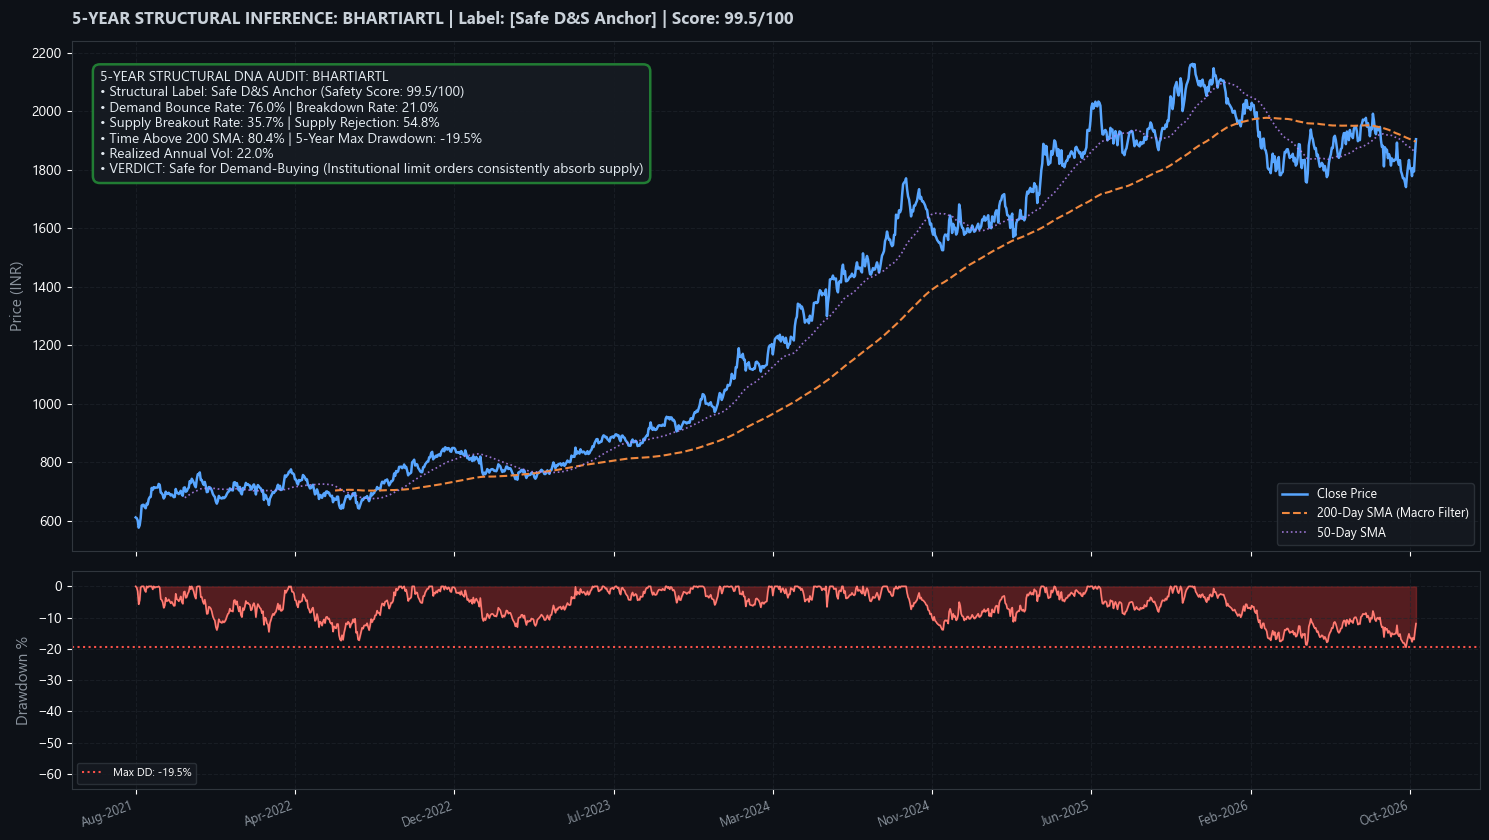

=== CASE STUDY 2: INSTITUTIONAL BANK ANCHOR (ICICIBANK) ===


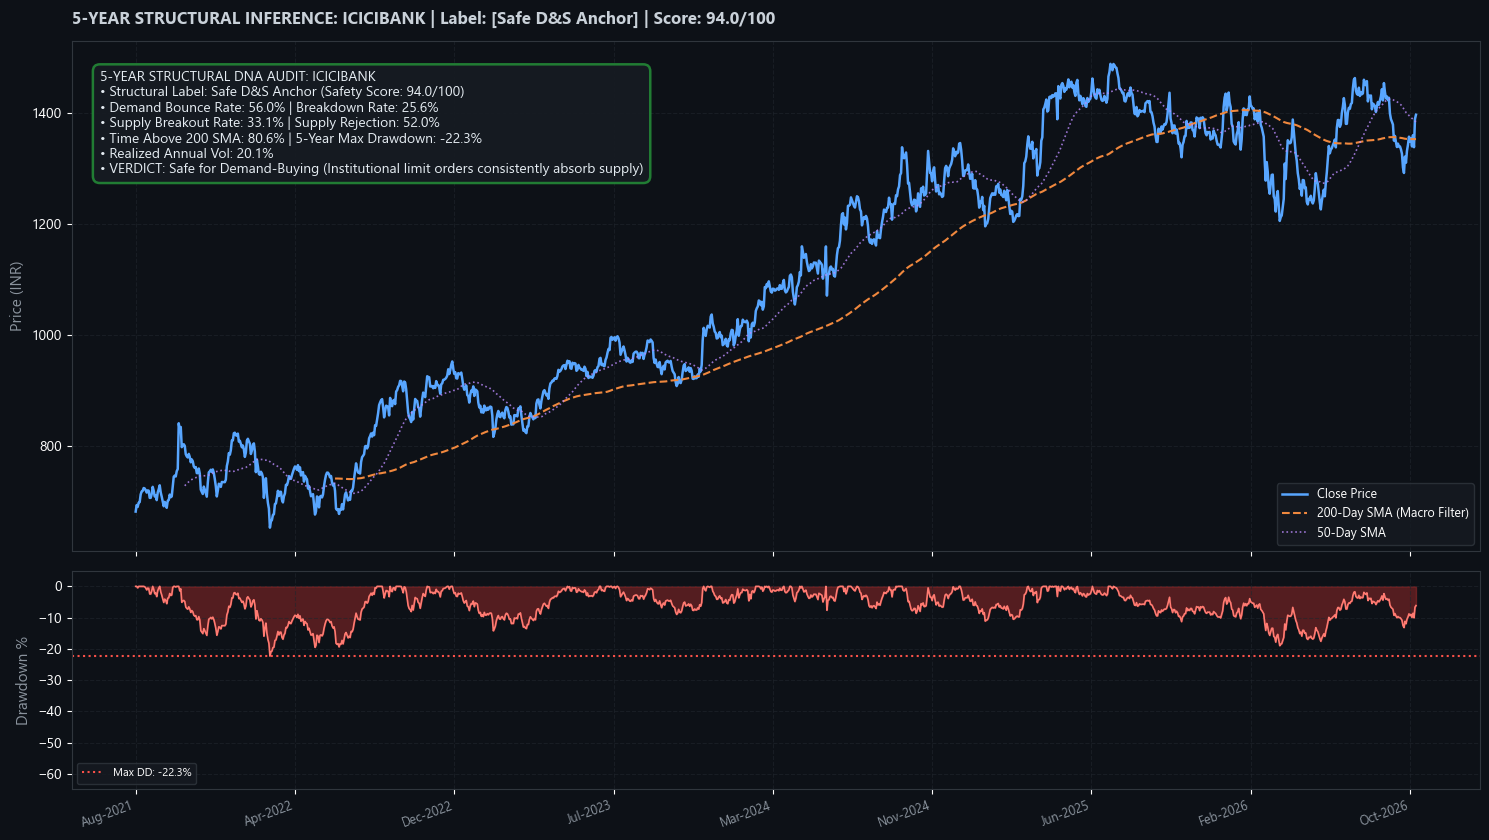

=== CASE STUDY 3: HIGH FALLING-ZONE RISK (ZEEL) ===


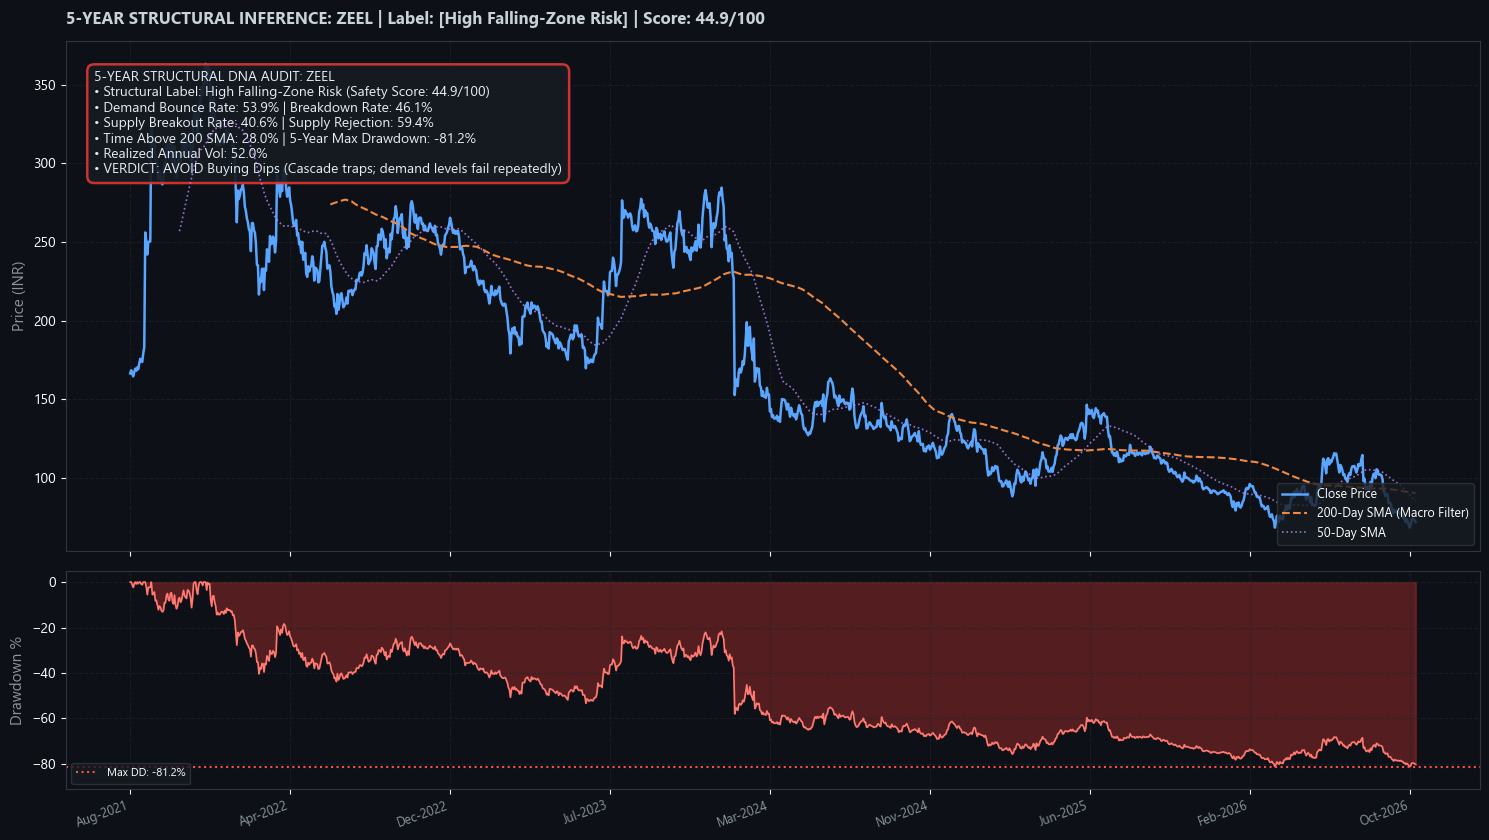

=== CASE STUDY 4: MEAN-REVERSION OSCILLATOR (TCS) ===


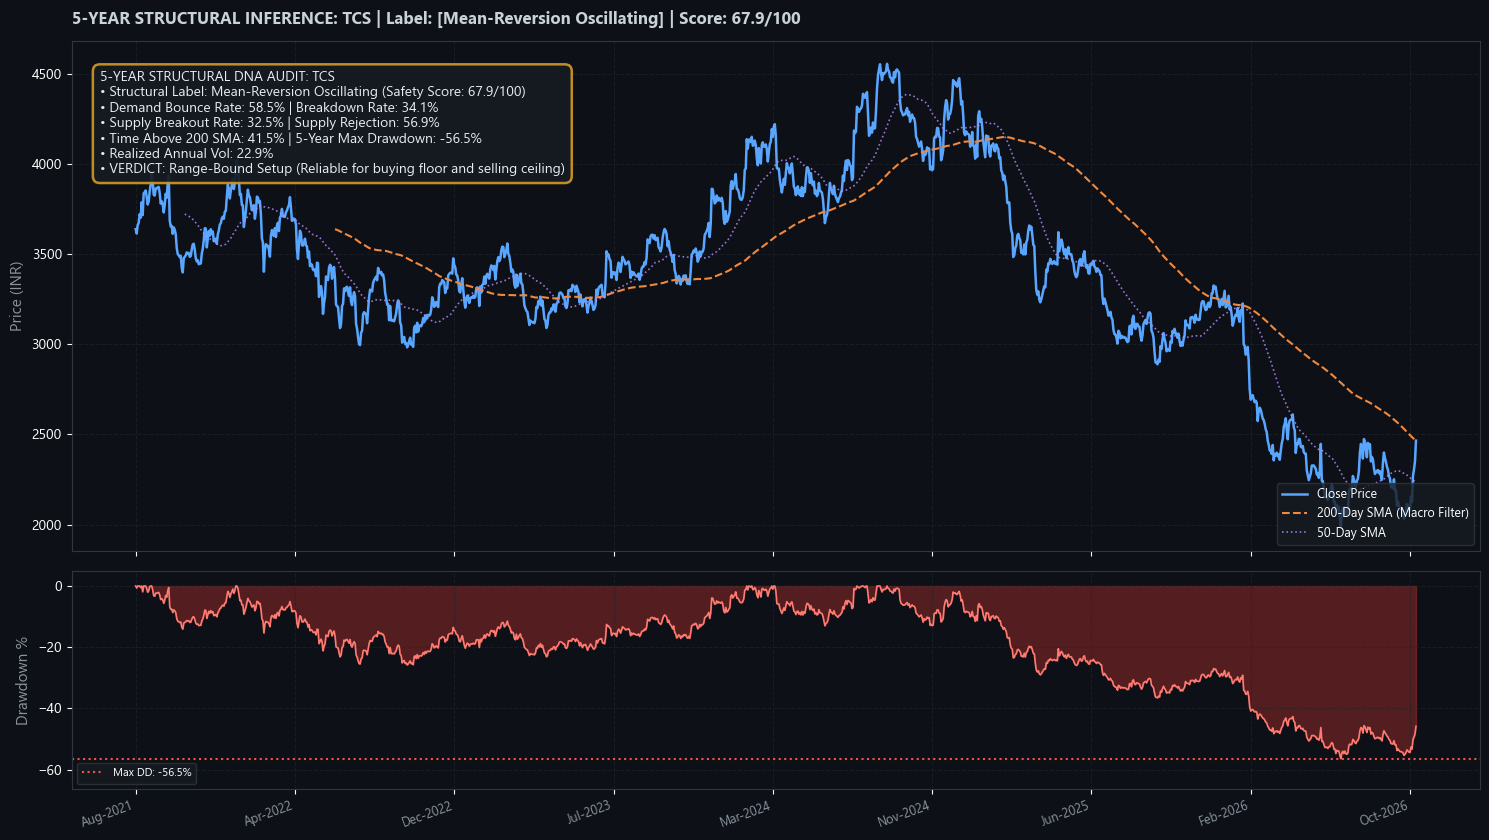

In [7]:
# Execute Step-by-Step Diagnostic Comparisons

# Case 1: Ultra-Safe D&S Anchor (BHARTIARTL - High support integrity, low drawdown)
print("=== CASE STUDY 1: PRIME SAFE ANCHOR (BHARTIARTL) ===")
plot_5y_structural_diagnostic('BHARTIARTL')

# Case 2: Institutional Safe Anchor (ICICIBANK - Consistent support bounces, >80% time above 200 SMA)
print("=== CASE STUDY 2: INSTITUTIONAL BANK ANCHOR (ICICIBANK) ===")
plot_5y_structural_diagnostic('ICICIBANK')

# Case 3: High Falling-Zone Risk Stock (ZEEL - Chronic breakdown of demand, deep -81% drawdown)
print("=== CASE STUDY 3: HIGH FALLING-ZONE RISK (ZEEL) ===")
plot_5y_structural_diagnostic('ZEEL')

# Case 4: Mean-Reversion Oscillator (TCS - Range-bound oscillation around macro SMA)
print("=== CASE STUDY 4: MEAN-REVERSION OSCILLATOR (TCS) ===")
plot_5y_structural_diagnostic('TCS')


---
## 🌊 Institutional Market Breadth & Internal Strength Engine
### Trend Analysis: % of Stocks Above 200 SMA vs. Daily Gainer Velocity

### 1. The Quantitative Problem Statement
Individual stock screening without broad **Market Breadth** creates a dangerous blind spot:
- **Bullish Distribution Traps**: An index or heavyweight basket can grind to new highs driven by 3–5 mega-cap stocks while the underlying universe is quietly deteriorating (fewer and fewer stocks holding above their 200-day moving average). Chasing breakouts during such phases leads to severe whipsaws.
- **Leading Accumulation Waves (Breadth Thrusts)**: At market bottoms or deep corrections, daily gainers surge violently across sectors before the headline index or the lagging 200 SMA can confirm the turn.

### 2. Dual-Horizon Breadth Framework
To gauge true internal strength, we track the dynamic interplay between two complementary metrics:
1. **Structural Breadth (Lagging / Macro Regime)**:
   $$\text{Breadth}_{200} = \frac{\text{Count of Stocks with } \text{Close}_t > \text{SMA}_{200}(t)}{\text{Total Universe}} \times 100\%$$
   - The 200-day SMA is the definitive institutional benchmark distinguishing secular bull cycles from distribution regimes.
2. **Velocity / Flow Momentum (Leading / Short-Term Breadth)**:
   $$\text{Daily Advance } \% = \frac{\text{Count of Gaining Stocks } (C_t > C_{t-1})}{\text{Total Universe}} \times 100\%$$
   - Smoothed via a 10-day moving average ($\text{SMA}_{10}(\text{Advance } \%)$) to filter single-day noise and reveal sustained capital inflows.

---

### 3. Brainstormed Institutional Insights for Market Strength
In addition to the 200 SMA and Daily Gainer ratio, quantitative desks track 5 internal pillars to detect expanding market strength:
1. **Moving Average Ribbon Breadth Stack (`% > 20 EMA`, `% > 50 SMA`, `% > 200 SMA`)**:
   - **Triple Bull Expansion**: When $\% > 20 \text{ EMA} > \% > 50 \text{ SMA} > \% > 200 \text{ SMA}$, confirming momentum is accelerating from short to long timeframes.
2. **Volume-Weighted Advance Thrust (Up Volume % vs. Down Volume %)**:
   - Volume confirms conviction. Days with $\ge 80\%$ Up Volume represent institutional accumulation where large funds are aggressively deploying capital.
3. **Cumulative Advance-Decline (A/D) Line & McClellan Oscillator**:
   - The slope of the cumulative A/D line confirms index trends; positive McClellan divergence ($> 0$) spots inflection points before price breaks out.
4. **Net 52-Week Highs vs. Lows (Leadership Expansion Index)**:
   - Tracks whether leadership is broadening (more stocks touching 52-week highs) or shrinking (new 52-week lows expanding).
5. **Composite Market Strength Index (CMSI, 0 to 100)**:
   - A synthesized, weighted institutional health gauge categorized into 4 distinct trading regimes:
     - 🟢 **Strong Expansion ($\ge 70$)**: High breakout follow-through; aggressive trend trading favored.
     - 🟡 **Selective Accumulation ($50 - 70$)**: Stock-specific market; buying demand zone pullbacks favored.
     - 🟠 **Choppy Consolidation ($35 - 50$)**: Mean reversion; tight risk management; take quick profits.
     - 🔴 **Structural Distribution ($< 35$)**: High cascade breakdown risk; defensive cash / hedging favored.


In [16]:
# Build Comprehensive Daily Market Breadth & Internal Strength Time-Series
print("Building 5-year Market Breadth & Internal Strength Panels across 115 F&O Equities...")

close_dict = {}
vol_dict = {}
high_dict = {}
low_dict = {}

for sym, df_s in universe_dfs.items():
    if len(df_s) >= 70:
        s_df = df_s.set_index('date')
        close_dict[sym] = s_df['close']
        vol_dict[sym] = s_df['volume']
        high_dict[sym] = s_df['high']
        low_dict[sym] = s_df['low']

df_closes = pd.DataFrame(close_dict).sort_index()
df_vols = pd.DataFrame(vol_dict).sort_index()
df_highs = pd.DataFrame(high_dict).sort_index()
df_lows = pd.DataFrame(low_dict).sort_index()

total_active = df_closes.notna().sum(axis=1)

# 1. Multi-Horizon Moving Average Breadth
sma200_panel = df_closes.rolling(200, min_periods=100).mean()
sma50_panel = df_closes.rolling(50, min_periods=25).mean()
ema20_panel = df_closes.ewm(span=20, min_periods=10, adjust=False).mean()

pct_above_200 = ((df_closes > sma200_panel).sum(axis=1) / sma200_panel.notna().sum(axis=1)) * 100.0
pct_above_50 = ((df_closes > sma50_panel).sum(axis=1) / sma50_panel.notna().sum(axis=1)) * 100.0
pct_above_20 = ((df_closes > ema20_panel).sum(axis=1) / ema20_panel.notna().sum(axis=1)) * 100.0

# 2. Daily Gainers / Losers Velocity
prev_closes = df_closes.shift(1)
is_gainer = (df_closes > prev_closes)
is_loser = (df_closes < prev_closes)
gainers_count = is_gainer.sum(axis=1)
losers_count = is_loser.sum(axis=1)
pct_gainers = (gainers_count / total_active) * 100.0
gainers_10sma = pct_gainers.rolling(10).mean()
gainers_20sma = pct_gainers.rolling(20).mean()

# 3. Advance-Decline & McClellan Breadth Oscillator
net_advances = gainers_count - losers_count
ad_line = net_advances.cumsum()
mcclellan_osc = net_advances.ewm(span=19, adjust=False).mean() - net_advances.ewm(span=39, adjust=False).mean()

# 4. Volume-Weighted Advance Thrust
up_volume = (df_vols * is_gainer).sum(axis=1)
down_volume = (df_vols * is_loser).sum(axis=1)
total_volume = up_volume + down_volume
pct_up_volume = (up_volume / total_volume) * 100.0
vol_thrust_10sma = pct_up_volume.rolling(10).mean()

# 5. Net 52-Week Highs vs. Lows
rolling_52wh = df_highs.rolling(250, min_periods=120).max()
rolling_52wl = df_lows.rolling(250, min_periods=120).min()
near_52wh_pct = ((df_closes >= rolling_52wh * 0.98).sum(axis=1) / total_active) * 100.0
near_52wl_pct = ((df_closes <= rolling_52wl * 1.02).sum(axis=1) / total_active) * 100.0
net_52w_high_low = near_52wh_pct - near_52wl_pct

# 6. Composite Market Strength Index (CMSI, 0 to 100)
cmsi_series = (
    pct_above_200 * 0.25 +
    pct_above_50 * 0.25 +
    pct_above_20 * 0.20 +
    gainers_10sma * 0.15 +
    vol_thrust_10sma * 0.15
).round(1)

# Assemble Master Breadth DataFrame
df_market_breadth = pd.DataFrame({
    'Total_Stocks': total_active,
    'Above_200_Count': (df_closes > sma200_panel).sum(axis=1),
    'Pct_Above_200': pct_above_200,
    'Pct_Above_50': pct_above_50,
    'Pct_Above_20': pct_above_20,
    'Daily_Gainers_Count': gainers_count,
    'Daily_Losers_Count': losers_count,
    'Pct_Daily_Gainers': pct_gainers,
    'Gainers_10SMA': gainers_10sma,
    'Gainers_20SMA': gainers_20sma,
    'Net_Advances': net_advances,
    'AD_Line': ad_line,
    'McClellan_Osc': mcclellan_osc,
    'Pct_Up_Volume': pct_up_volume,
    'Vol_Thrust_10SMA': vol_thrust_10sma,
    'Net_52W_High_Low': net_52w_high_low,
    'CMSI': cmsi_series
}).dropna(subset=['Pct_Above_200'])

print(f"\nSuccessfully compiled {len(df_market_breadth)} historical market sessions.")
print(f"History Range: {df_market_breadth.index.min().strftime('%Y-%m-%d')} to {df_market_breadth.index.max().strftime('%Y-%m-%d')}")
print("\n--- ANNUAL MARKET BREADTH & INTERNAL REGIME REGRESSION ---")
annual_reg = df_market_breadth.copy()
annual_reg['Year'] = annual_reg.index.year
print(annual_reg.groupby('Year')[['Pct_Above_200', 'Pct_Above_50', 'Pct_Daily_Gainers', 'Vol_Thrust_10SMA', 'CMSI']].mean().round(1))


Building 5-year Market Breadth & Internal Strength Panels across 115 F&O Equities...

Successfully compiled 1181 historical market sessions.
History Range: 2022-01-13 to 2026-10-16

--- ANNUAL MARKET BREADTH & INTERNAL REGIME REGRESSION ---
      Pct_Above_200  Pct_Above_50  Pct_Daily_Gainers  Vol_Thrust_10SMA  CMSI
Year                                                                        
2022           48.8          52.5               50.3              54.6  51.5
2023           77.3          64.2               53.2              56.9  64.3
2024           78.5          59.6               51.3              55.3  62.0
2025           50.3          52.6               50.0              53.7  51.7
2026           45.8          45.9               48.1              51.4  47.4


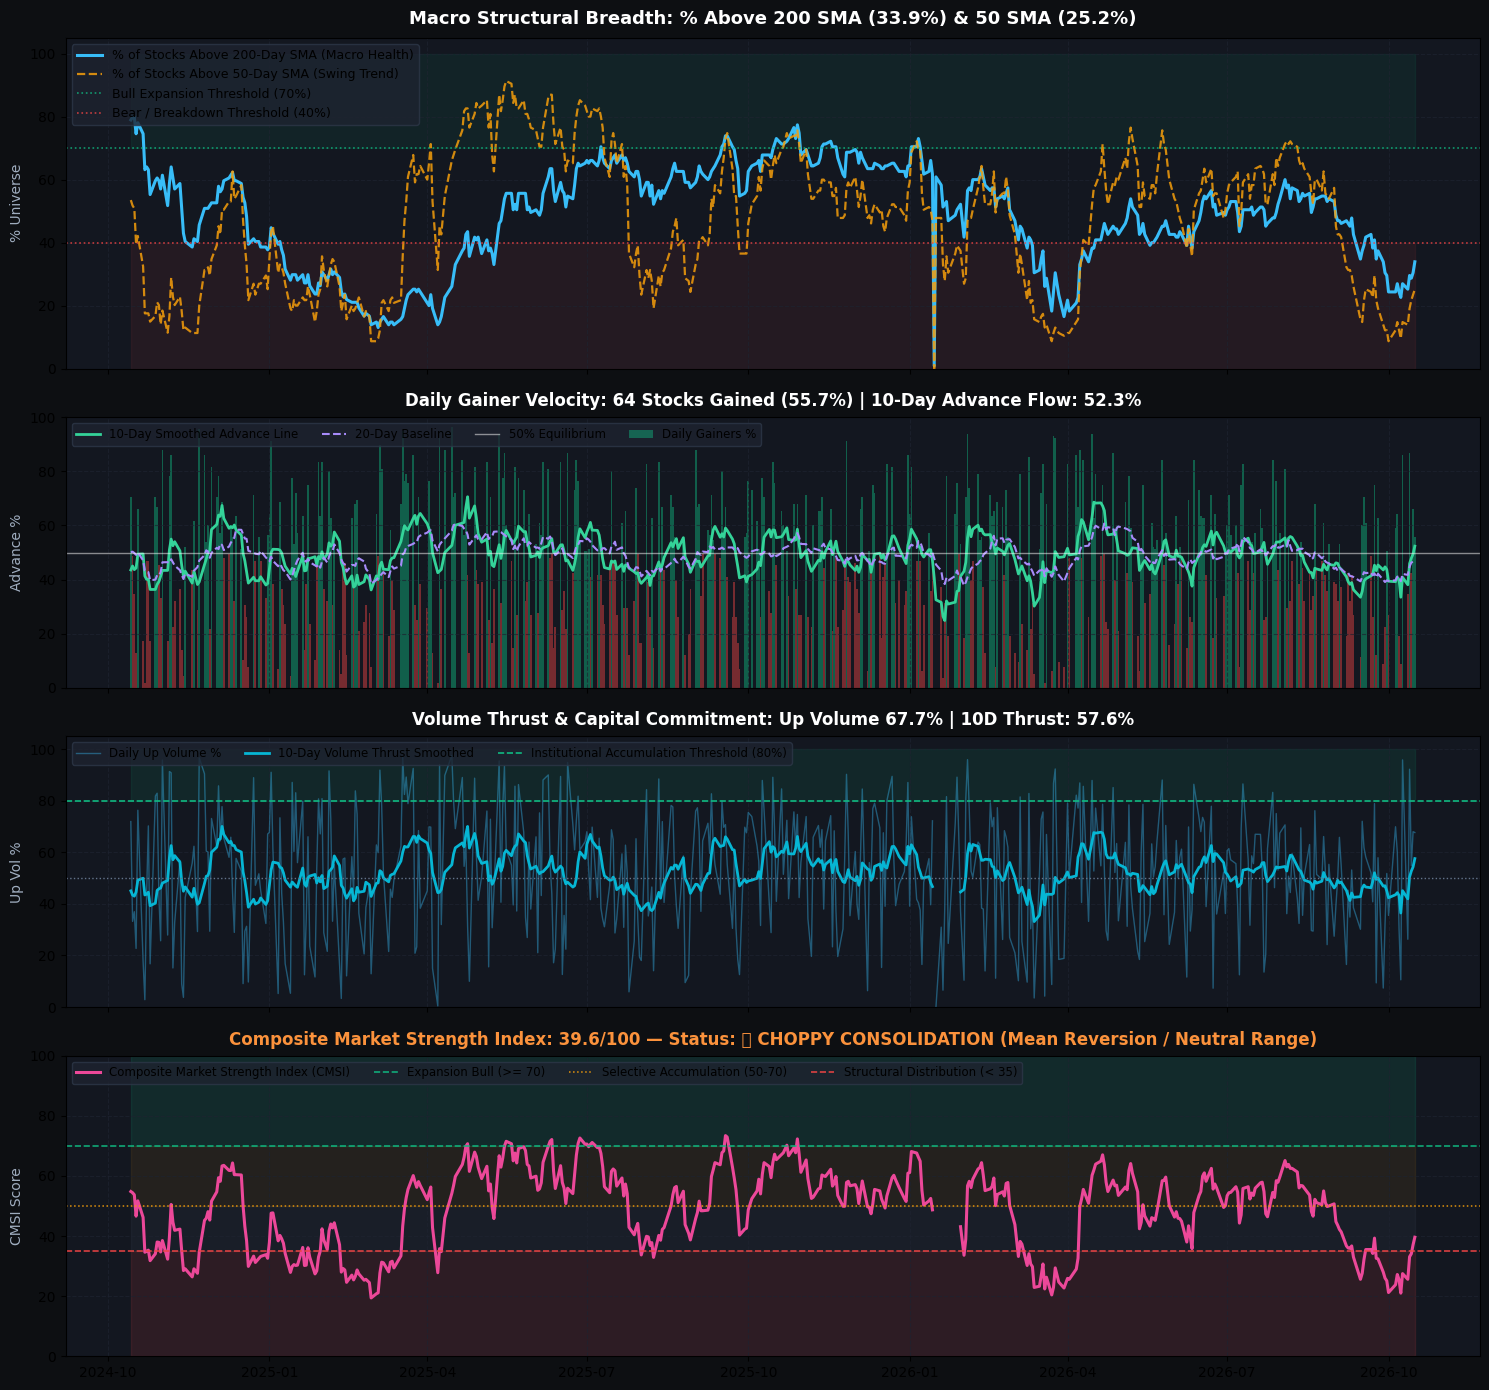

In [17]:
# Multi-Panel Institutional Market Breadth & Internal Strength Diagnostic Chart
def plot_market_breadth_diagnostic(lookback_days=500):
    """
    Plots a 4-panel institutional market strength dashboard:
    1. Macro Structural Breadth: % of Stocks Above 200 SMA & 50 SMA with Regime Bands
    2. Velocity Flow: Daily Gainer % vs. 10-Day & 20-Day Smoothed Advance Lines
    3. Volume Thrust: Daily Up Volume % vs. 80% Institutional Accumulation Threshold
    4. Composite Market Strength Index (CMSI) with Expansion/Distribution Regimes
    """
    plot_df = df_market_breadth.iloc[-lookback_days:].copy()
    dates = plot_df.index
    
    fig, axes = plt.subplots(4, 1, figsize=(15, 14), sharex=True, gridspec_kw={'height_ratios': [2.2, 1.8, 1.8, 2.0]})
    fig.patch.set_facecolor('#0d0f12')
    
    # ----------------------------------------------------
    # PANEL 1: Structural Breadth (% Above 200 & 50 SMA)
    # ----------------------------------------------------
    ax1 = axes[0]
    ax1.set_facecolor('#131720')
    ax1.plot(dates, plot_df['Pct_Above_200'], color='#38bdf8', lw=2.2, label='% of Stocks Above 200-Day SMA (Macro Health)')
    ax1.plot(dates, plot_df['Pct_Above_50'], color='#f59e0b', lw=1.6, alpha=0.85, ls='--', label='% of Stocks Above 50-Day SMA (Swing Trend)')
    
    # Threshold zones
    ax1.axhline(70.0, color='#10b981', ls=':', lw=1.2, alpha=0.8, label='Bull Expansion Threshold (70%)')
    ax1.axhline(40.0, color='#ef4444', ls=':', lw=1.2, alpha=0.8, label='Bear / Breakdown Threshold (40%)')
    ax1.fill_between(dates, 70, 100, color='#10b981', alpha=0.08)
    ax1.fill_between(dates, 0, 40, color='#ef4444', alpha=0.08)
    
    curr_200 = plot_df['Pct_Above_200'].iloc[-1]
    curr_50 = plot_df['Pct_Above_50'].iloc[-1]
    ax1.set_title(f"Macro Structural Breadth: % Above 200 SMA ({curr_200:.1f}%) & 50 SMA ({curr_50:.1f}%)", 
                  fontsize=13, fontweight='bold', color='#ffffff', pad=10)
    ax1.set_ylabel("% Universe", fontsize=10, color='#a0aec0')
    ax1.set_ylim(0, 105)
    ax1.legend(loc='upper left', facecolor='#1e2330', edgecolor='#2d3748', fontsize=9)
    ax1.grid(True, color='#1e2330', ls='--', alpha=0.7)
    
    # ----------------------------------------------------
    # PANEL 2: Daily Gainer Velocity & Flow Momentum
    # ----------------------------------------------------
    ax2 = axes[1]
    ax2.set_facecolor('#131720')
    
    bar_colors = ['#10b981' if g >= 50.0 else '#ef4444' for g in plot_df['Pct_Daily_Gainers']]
    ax2.bar(dates, plot_df['Pct_Daily_Gainers'], color=bar_colors, width=1.0, alpha=0.45, label='Daily Gainers %')
    ax2.plot(dates, plot_df['Gainers_10SMA'], color='#34d399', lw=2.0, label='10-Day Smoothed Advance Line')
    ax2.plot(dates, plot_df['Gainers_20SMA'], color='#a78bfa', lw=1.5, ls='--', label='20-Day Baseline')
    ax2.axhline(50.0, color='#ffffff', ls='-', lw=1.0, alpha=0.5, label='50% Equilibrium')
    
    curr_gainers = plot_df['Pct_Daily_Gainers'].iloc[-1]
    curr_gain_count = int(plot_df['Daily_Gainers_Count'].iloc[-1])
    curr_10sma = plot_df['Gainers_10SMA'].iloc[-1]
    ax2.set_title(f"Daily Gainer Velocity: {curr_gain_count} Stocks Gained ({curr_gainers:.1f}%) | 10-Day Advance Flow: {curr_10sma:.1f}%", 
                  fontsize=12, fontweight='bold', color='#ffffff', pad=8)
    ax2.set_ylabel("Advance %", fontsize=10, color='#a0aec0')
    ax2.set_ylim(0, 100)
    ax2.legend(loc='upper left', facecolor='#1e2330', edgecolor='#2d3748', fontsize=8.5, ncol=4)
    ax2.grid(True, color='#1e2330', ls='--', alpha=0.7)
    
    # ----------------------------------------------------
    # PANEL 3: Volume Thrust (Up Volume % vs Down Volume %)
    # ----------------------------------------------------
    ax3 = axes[2]
    ax3.set_facecolor('#131720')
    ax3.plot(dates, plot_df['Pct_Up_Volume'], color='#38bdf8', lw=1.0, alpha=0.4, label='Daily Up Volume %')
    ax3.plot(dates, plot_df['Vol_Thrust_10SMA'], color='#06b6d4', lw=2.0, label='10-Day Volume Thrust Smoothed')
    ax3.axhline(80.0, color='#10b981', ls='--', lw=1.2, label='Institutional Accumulation Threshold (80%)')
    ax3.axhline(50.0, color='#64748b', ls=':', lw=1.0)
    ax3.fill_between(dates, 80, 100, color='#10b981', alpha=0.1)
    
    curr_upvol = plot_df['Pct_Up_Volume'].iloc[-1]
    curr_vt10 = plot_df['Vol_Thrust_10SMA'].iloc[-1]
    ax3.set_title(f"Volume Thrust & Capital Commitment: Up Volume {curr_upvol:.1f}% | 10D Thrust: {curr_vt10:.1f}%", 
                  fontsize=12, fontweight='bold', color='#ffffff', pad=8)
    ax3.set_ylabel("Up Vol %", fontsize=10, color='#a0aec0')
    ax3.set_ylim(0, 105)
    ax3.legend(loc='upper left', facecolor='#1e2330', edgecolor='#2d3748', fontsize=8.5, ncol=3)
    ax3.grid(True, color='#1e2330', ls='--', alpha=0.7)
    
    # ----------------------------------------------------
    # PANEL 4: Composite Market Strength Index (CMSI, 0-100)
    # ----------------------------------------------------
    ax4 = axes[3]
    ax4.set_facecolor('#131720')
    
    ax4.plot(dates, plot_df['CMSI'], color='#ec4899', lw=2.2, label='Composite Market Strength Index (CMSI)')
    
    ax4.axhline(70.0, color='#10b981', ls='--', lw=1.2, alpha=0.9, label='Expansion Bull (>= 70)')
    ax4.axhline(50.0, color='#f59e0b', ls=':', lw=1.1, alpha=0.9, label='Selective Accumulation (50-70)')
    ax4.axhline(35.0, color='#ef4444', ls='--', lw=1.2, alpha=0.9, label='Structural Distribution (< 35)')
    
    ax4.fill_between(dates, 70, 100, color='#10b981', alpha=0.12)
    ax4.fill_between(dates, 50, 70, color='#f59e0b', alpha=0.08)
    ax4.fill_between(dates, 35, 50, color='#64748b', alpha=0.08)
    ax4.fill_between(dates, 0, 35, color='#ef4444', alpha=0.12)
    
    curr_cmsi = plot_df['CMSI'].iloc[-1]
    if curr_cmsi >= 70:
        regime_txt = "🟢 STRONG BULL EXPANSION (Aggressive Longs / Breakouts Favored)"
        regime_col = '#10b981'
    elif curr_cmsi >= 50:
        regime_txt = "🟡 SELECTIVE ACCUMULATION (Stock-Picking / Demand Dip Buying)"
        regime_col = '#f59e0b'
    elif curr_cmsi >= 35:
        regime_txt = "🟠 CHOPPY CONSOLIDATION (Mean Reversion / Neutral Range)"
        regime_col = '#fb923c'
    else:
        regime_txt = "🔴 STRUCTURAL DISTRIBUTION (Defensive / Tight Stops / Cash)"
        regime_col = '#ef4444'
        
    ax4.set_title(f"Composite Market Strength Index: {curr_cmsi:.1f}/100 — Status: {regime_txt}", 
                  fontsize=12, fontweight='bold', color=regime_col, pad=8)
    ax4.set_ylabel("CMSI Score", fontsize=10, color='#a0aec0')
    ax4.set_ylim(0, 100)
    ax4.legend(loc='upper left', facecolor='#1e2330', edgecolor='#2d3748', fontsize=8.5, ncol=4)
    ax4.grid(True, color='#1e2330', ls='--', alpha=0.7)
    
    plt.tight_layout()
    plt.show()

plot_market_breadth_diagnostic(lookback_days=500)


In [18]:
# Executive Market Strength & Breadth Leadership Diagnostic Table
latest = df_market_breadth.iloc[-1]
prev_1w = df_market_breadth.iloc[-6]
prev_1m = df_market_breadth.iloc[-22]

summary_records = [
    {
        'Metric': 'Stocks Above 200-Day SMA',
        'Current': f"{int(latest['Above_200_Count'])} / {int(latest['Total_Stocks'])} ({latest['Pct_Above_200']:.1f}%)",
        '1-Week Ago': f"{prev_1w['Pct_Above_200']:.1f}%",
        '1-Month Ago': f"{prev_1m['Pct_Above_200']:.1f}%",
        '1-Month Shift': f"{latest['Pct_Above_200'] - prev_1m['Pct_Above_200']:+.1f}%",
        'Significance': 'Institutional macro trendline; expansion confirms broad sector health'
    },
    {
        'Metric': 'Stocks Above 50-Day SMA',
        'Current': f"{latest['Pct_Above_50']:.1f}%",
        '1-Week Ago': f"{prev_1w['Pct_Above_50']:.1f}%",
        '1-Month Ago': f"{prev_1m['Pct_Above_50']:.1f}%",
        '1-Month Shift': f"{latest['Pct_Above_50'] - prev_1m['Pct_Above_50']:+.1f}%",
        'Significance': 'Intermediate swing breadth; crosses above 200 SMA signal expansion waves'
    },
    {
        'Metric': 'Stocks Above 20-Day EMA',
        'Current': f"{latest['Pct_Above_20']:.1f}%",
        '1-Week Ago': f"{prev_1w['Pct_Above_20']:.1f}%",
        '1-Month Ago': f"{prev_1m['Pct_Above_20']:.1f}%",
        '1-Month Shift': f"{latest['Pct_Above_20'] - prev_1m['Pct_Above_20']:+.1f}%",
        'Significance': 'Fast short-term momentum; leads 50 & 200 SMA inflections by 10-15 days'
    },
    {
        'Metric': 'Daily Gainers Velocity',
        'Current': f"{int(latest['Daily_Gainers_Count'])} Gainers ({latest['Pct_Daily_Gainers']:.1f}%)",
        '1-Week Ago': f"{prev_1w['Pct_Daily_Gainers']:.1f}%",
        '1-Month Ago': f"{prev_1m['Pct_Daily_Gainers']:.1f}%",
        '1-Month Shift': f"{latest['Pct_Daily_Gainers'] - prev_1m['Pct_Daily_Gainers']:+.1f}%",
        'Significance': 'Daily participation breadth; > 65% signals broad-based buying thrust'
    },
    {
        'Metric': '10-Day Smoothed Advance Flow',
        'Current': f"{latest['Gainers_10SMA']:.1f}%",
        '1-Week Ago': f"{prev_1w['Gainers_10SMA']:.1f}%",
        '1-Month Ago': f"{prev_1m['Gainers_10SMA']:.1f}%",
        '1-Month Shift': f"{latest['Gainers_10SMA'] - prev_1m['Gainers_10SMA']:+.1f}%",
        'Significance': 'Filters single-day whipsaws; sustained > 50% confirms buyers in control'
    },
    {
        'Metric': 'Volume Thrust (Up Volume %)',
        'Current': f"{latest['Pct_Up_Volume']:.1f}%",
        '1-Week Ago': f"{prev_1w['Pct_Up_Volume']:.1f}%",
        '1-Month Ago': f"{prev_1m['Pct_Up_Volume']:.1f}%",
        '1-Month Shift': f"{latest['Pct_Up_Volume'] - prev_1m['Pct_Up_Volume']:+.1f}%",
        'Significance': 'Turnover commitment; > 80% marks institutional accumulation days'
    },
    {
        'Metric': 'McClellan Breadth Oscillator',
        'Current': f"{latest['McClellan_Osc']:+.2f}",
        '1-Week Ago': f"{prev_1w['McClellan_Osc']:+.2f}",
        '1-Month Ago': f"{prev_1m['McClellan_Osc']:+.2f}",
        '1-Month Shift': f"{latest['McClellan_Osc'] - prev_1m['McClellan_Osc']:+.2f}",
        'Significance': 'Breadth momentum; positive cross indicates acceleration of net buying'
    },
    {
        'Metric': 'Composite Market Strength (CMSI)',
        'Current': f"{latest['CMSI']:.1f} / 100",
        '1-Week Ago': f"{prev_1w['CMSI']:.1f}",
        '1-Month Ago': f"{prev_1m['CMSI']:.1f}",
        '1-Month Shift': f"{latest['CMSI'] - prev_1m['CMSI']:+.1f}",
        'Significance': 'Multi-factor composite gauge synthesized across all 5 breadth dimensions'
    }
]

df_summary_report = pd.DataFrame(summary_records)
print("=== TRADEKRIYA INSTITUTIONAL MARKET STRENGTH REPORT ===")
print(f"Data Cut: {latest.name.strftime('%A, %d %B %Y')}")
print(f"Market Regime: {'BULL EXPANSION' if latest['CMSI']>=70 else ('SELECTIVE ACCUMULATION' if latest['CMSI']>=50 else ('CHOPPY NEUTRAL' if latest['CMSI']>=35 else 'DISTRIBUTION RISK'))}\n")
print(df_summary_report[['Metric', 'Current', '1-Month Shift', 'Significance']].to_string(index=False))


=== TRADEKRIYA INSTITUTIONAL MARKET STRENGTH REPORT ===
Data Cut: Friday, 16 October 2026
Market Regime: CHOPPY NEUTRAL

                          Metric            Current 1-Month Shift                                                             Significance
        Stocks Above 200-Day SMA   39 / 115 (33.9%)         -3.5%    Institutional macro trendline; expansion confirms broad sector health
         Stocks Above 50-Day SMA              25.2%        +10.4% Intermediate swing breadth; crosses above 200 SMA signal expansion waves
         Stocks Above 20-Day EMA              41.7%        +30.4%   Fast short-term momentum; leads 50 & 200 SMA inflections by 10-15 days
          Daily Gainers Velocity 64 Gainers (55.7%)         -4.3%     Daily participation breadth; > 65% signals broad-based buying thrust
    10-Day Smoothed Advance Flow              52.3%        +16.7%  Filters single-day whipsaws; sustained > 50% confirms buyers in control
     Volume Thrust (Up Volume %)             